# Gaussian random fields: U-Net output vs. the analytic linear estimator

Code for Sect. 3.1 and 3.2 of *Optimal cosmological cross-correlation analysis with U-Net-based processing* (W. Yan, D. Gruen, O. Friedrich, A. Kovács). It reproduces Figs. 2 and 3 and Tables 1 and 2.

A 1D U-Net is trained to transform an input field $\mathbf{I}$ into an output $\mathbf{O}$ that is maximally Pearson-correlated with a target field $\mathbf{T}$ (loss of Eq. 2). For jointly Gaussian fields the optimal transformation is known analytically: the linear filter $W(k) = P_{IT}(k)/P_{II}(k)$ of Eq. (7). In both cases below this filter reduces to a low-pass filter of the input, which defines the linear estimator $\mathbf{L}$ against which the network output is compared.

All shared code (field generation, network, training, estimators, plotting) is in `unet_tools.py`. Training needs a GPU; generating the training set uses all CPU cores and a few GB of memory.

In [2]:
import os
import sys
from pathlib import Path

# Make unet_tools.py (stored next to this notebook) importable and write figures/weights
# next to the notebook, even if the kernel was started in another directory.
_nb_file = globals().get("__vsc_ipynb_file__")          # set by VS Code
NB_DIR = Path(_nb_file).parent if _nb_file else Path.cwd()
if not (NB_DIR / "unet_tools.py").exists():
    raise FileNotFoundError(f"unet_tools.py not found in {NB_DIR}; start the notebook from its own folder")
sys.path.insert(0, str(NB_DIR))
os.chdir(NB_DIR)

import numpy as np
import matplotlib.pyplot as plt
import torch

import unet_tools as ut
from unet_tools import gaussian_random_field, K_CUTOFF

ut.set_paper_style()
FIG_DIR = "figures"
print("device:", ut.get_device())

device: cuda


## Sect. 3.1 — Gaussian random fields with shared seeds

$\mathbf{I} = A_1$ and $\mathbf{T} = A_2$, where $A_1$ is a Gaussian random field with the broken-power-law spectrum of Eq. (10) and $A_2$ is generated from the **same random seed** with a high-frequency cutoff at mode $k = 20$. The two fields are identical below the cutoff and $\mathbf{T}$ has no power above it, so $P_{II} = P$, $P_{IT} = P_{TT} = P\,\Theta$, $W(k) = \Theta(k)$ and the optimal linear estimator $\mathbf{L}$ is the low-pass filtered input, i.e. $\mathbf{L} = \mathbf{T}$.

In [3]:
def make_pair_shared_seed(seed):
    """I = A1 (full spectrum), T = A2 (same seed, modes above the cutoff removed)."""
    A1 = gaussian_random_field(seed, amplitude=1.0)
    A2 = gaussian_random_field(seed, amplitude=1.0, k_cutoff=K_CUTOFF)
    return A1, A2

In [4]:
# ---- parameters (Sect. 3.1) ----
N_TRAIN, N_VAL, N_TEST = 100_000, 100, 200   # pairs for training / validation / test
EPOCHS, LR, BATCH_SIZE = 5, 1e-5, 50
N_REAL = 100                                  # realizations averaged for the power spectra
N_TABLE = 200                                 # realizations averaged for the table

### Data

Training, validation and test pairs are drawn from disjoint seed ranges. All three sets are divided by one global constant so that the fields have roughly unit variance (the raw fields have a standard deviation of a few $10^{-3}$); the loss is scale free, so this changes nothing about the objective, and one common factor keeps every amplitude ratio between $\mathbf{I}$ and $\mathbf{T}$ intact.

In [5]:
training   = ut.generate_dataset(N_TRAIN, make_pair_shared_seed, seed=0)
validation = ut.generate_dataset(N_VAL,   make_pair_shared_seed, seed=500_000)
test_data  = ut.generate_dataset(N_TEST,  make_pair_shared_seed, seed=600_000)

scale = ut.generate_dataset(64, make_pair_shared_seed, seed=900_000).data.std().item()
training, validation, test_data = (ut.rescale_dataset(d, scale) for d in (training, validation, test_data))
print(f"fields divided by {scale:.3e}")

fields divided by 3.075e-03


### Training

Depth-3 U-Net with channels 64/128/256 and kernels 321/161/81 (Fig. 1), here in the periodic variant `UNetCircular` (circular padding, interpolation up-sampling, LeakyReLU hidden layers and a linear output layer, since the Gaussian target takes negative values). Adam optimizer, negative Pearson correlation as the loss.

In [6]:
model = ut.UNetCircular(negative_slope=0.1, linear_output=True)
model = ut.train_model(model, training, validation, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE)
torch.save(model.state_dict(), "unet_gaussian_shared_seed.pt")

Epoch 1/5
  loss:  0.535036  [     0/100000]
  loss: -0.995046  [ 25000/100000]
  loss: -0.995686  [ 50000/100000]
  loss: -0.996071  [ 75000/100000]
  validation loss: -0.996136
Epoch 2/5
  loss: -0.996428  [     0/100000]
  loss: -0.996454  [ 25000/100000]
  loss: -0.995919  [ 50000/100000]
  loss: -0.995990  [ 75000/100000]
  validation loss: -0.996353
Epoch 3/5
  loss: -0.995994  [     0/100000]
  loss: -0.995992  [ 25000/100000]
  loss: -0.995934  [ 50000/100000]
  loss: -0.996489  [ 75000/100000]
  validation loss: -0.996536
Epoch 4/5
  loss: -0.995965  [     0/100000]
  loss: -0.996940  [ 25000/100000]
  loss: -0.996388  [ 50000/100000]
  loss: -0.996607  [ 75000/100000]
  validation loss: -0.996630
Epoch 5/5
  loss: -0.996128  [     0/100000]
  loss: -0.996597  [ 25000/100000]
  loss: -0.996478  [ 50000/100000]
  loss: -0.996535  [ 75000/100000]
  validation loss: -0.996679


### Fig. 2a — one realization in real space

$\mathbf{T}$ and $\mathbf{O}$ are normalized to zero mean and unit variance. The lower panel shows $\mathbf{O} - \mathbf{T}$ (here $\mathbf{L} = \mathbf{T}$); the oscillation at the cutoff scale comes from the network's roll-off not being an exact cutoff.

Saved figure to: figures/fig2a_gaussian_shared_seed_fields.pdf


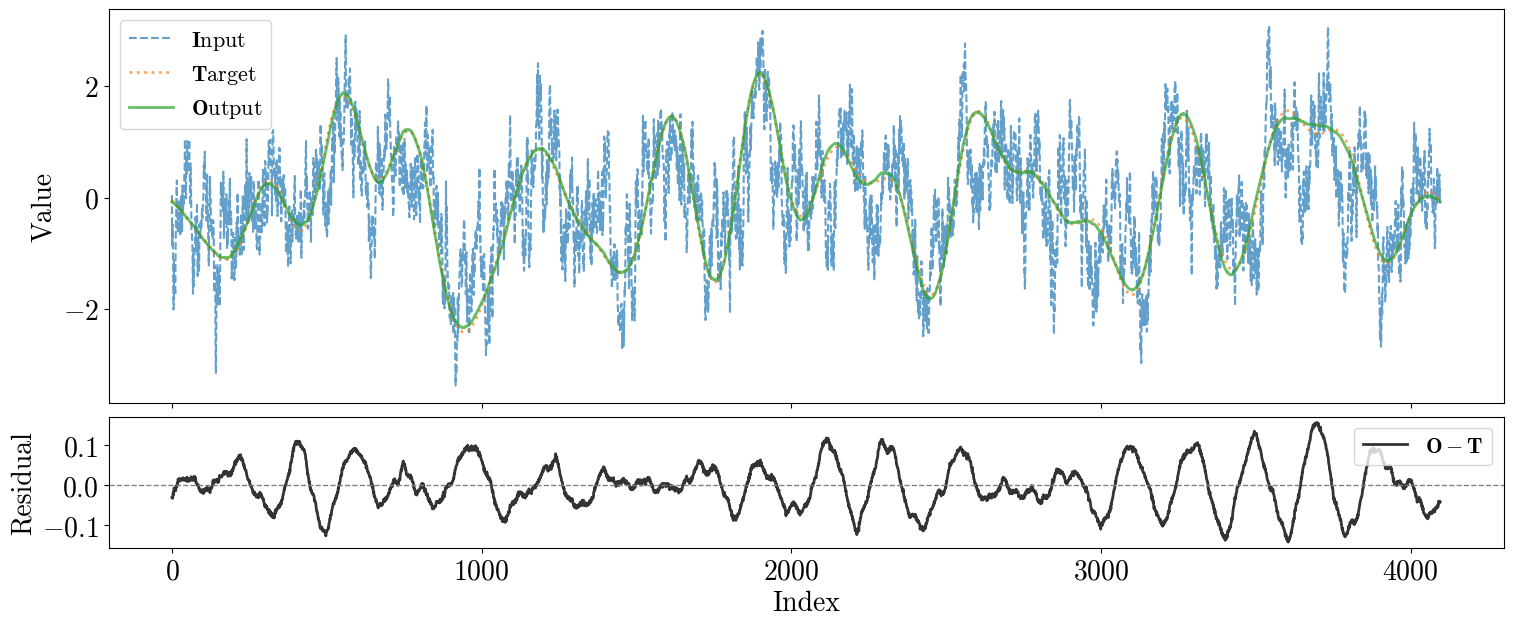

In [7]:
I, T = ut.get_fields(test_data, 0)
O = ut.predict(model, I)
I_n, T_n, O_n = ut.normalize(I), ut.normalize(T), ut.normalize(O)

fig = ut.plot_fields(
    [(I_n, ut.LABEL_I, ut.STYLE_I), (T_n, ut.LABEL_T, ut.STYLE_T), (O_n, ut.LABEL_O, ut.STYLE_O)],
    residuals=[(O_n - T_n, r"$\mathbf{O} - \mathbf{T}$", ut.STYLE_RESIDUAL)],
)
ut.save_figure(fig, "fig2a_gaussian_shared_seed_fields.pdf", FIG_DIR)
plt.show()

### Fig. 2b — power spectra, mean of 100 realizations

Each field is normalized to unit variance; the input spectrum is additionally rescaled so that it matches the target at low $k$. The output power drops by about two orders of magnitude beyond the cutoff.

Saved figure to: figures/fig2b_gaussian_shared_seed_power_spectra.pdf


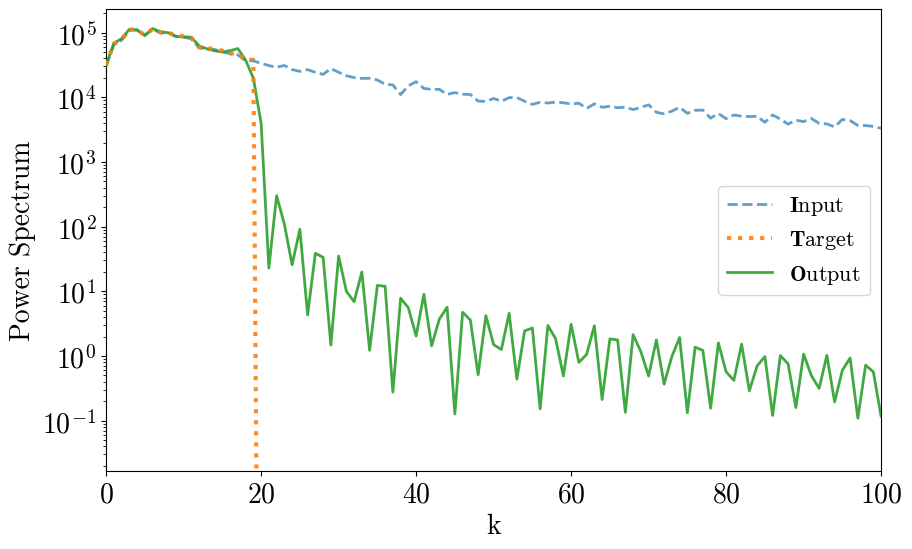

In [8]:
I_stack, T_stack = ut.get_fields(test_data, range(N_REAL))
O_stack = ut.predict(model, I_stack)

fig = ut.plot_power_spectra(ut.mean_powerspectrum(I_stack),
                            ut.mean_powerspectrum(T_stack),
                            ut.mean_powerspectrum(O_stack), floor_factor=1e5)
ut.save_figure(fig, "fig2b_gaussian_shared_seed_power_spectra.pdf", FIG_DIR)
plt.show()

### Table 1 — Pearson correlation with $\mathbf{T}$, mean and scatter over the test realizations

In [9]:
table1 = ut.correlation_table(test_data, {
    "I": lambda I: I,
    "L": ut.low_pass_filter,                  # optimal linear estimator, here L = T
    "O": lambda I: ut.predict(model, I),
}, n=N_TABLE)

Pearson correlation with T, mean +- std over 200 realizations
     I vs T : 0.698 +- 0.049
     L vs T : 0.997 +- 0.003
     O vs T : 0.997 +- 0.002


## Sect. 3.2 — Gaussian random fields with independent seeds

$\mathbf{I} = A_1 + A_2$ and $\mathbf{T} = A_2$, where $A_1$ and $A_2$ are now generated from **independent seeds** ($A_2$ again band limited to $k \le 20$). This gives $P_{II} = P\,(1+\Theta)$ and $P_{IT} = P_{TT} = P\,\Theta$, so $W(k) = \Theta/(1+\Theta)$, i.e. $1/2$ below the cutoff and $0$ above: $\mathbf{L}$ is again the low-pass filtered input, now with $r_{\max}^2 = 1/2$ at best.

In [10]:
A2_AMPLITUDE = 1.0   # amplitude of A2 relative to A1 (equal amplitudes, as assumed for W = 1/2 in the paper)
SEED_OFFSET = 1_000_000

def make_pair_independent_seeds(seed):
    """I = A1 + A2, T = A2, with A1 and A2 drawn from independent seeds."""
    A1 = gaussian_random_field(seed, amplitude=1.0)
    A2 = gaussian_random_field(seed + SEED_OFFSET, amplitude=A2_AMPLITUDE, k_cutoff=K_CUTOFF)
    return A1 + A2, A2

In [11]:
# ---- parameters (Sect. 3.2) ----
N_TRAIN, N_VAL, N_TEST = 50_000, 100, 200
EPOCHS, LR, BATCH_SIZE = 5, 1e-4, 50
N_REAL = 100
N_TABLE = 200

In [12]:
training   = ut.generate_dataset(N_TRAIN, make_pair_independent_seeds, seed=0)
validation = ut.generate_dataset(N_VAL,   make_pair_independent_seeds, seed=500_000)
test_data  = ut.generate_dataset(N_TEST,  make_pair_independent_seeds, seed=600_000)

scale = ut.generate_dataset(64, make_pair_independent_seeds, seed=900_000).data.std().item()
training, validation, test_data = (ut.rescale_dataset(d, scale) for d in (training, validation, test_data))
print(f"fields divided by {scale:.3e}")

fields divided by 3.777e-03


In [ ]:
model = ut.UNetCircular(negative_slope=0.1, linear_output=True)
model = ut.train_model(model, training, validation, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE)
torch.save(model.state_dict(), "unet_gaussian_independent_seeds.pt")

Epoch 1/5
  loss:  0.340801  [     0/ 50000]
  loss: -0.701716  [ 25000/ 50000]
  validation loss: -0.685869
Epoch 2/5
  loss: -0.699555  [     0/ 50000]
  loss: -0.687701  [ 25000/ 50000]
  validation loss: -0.685863
Epoch 3/5
  loss: -0.687220  [     0/ 50000]
  loss: -0.699108  [ 25000/ 50000]


### Fig. 3a — one realization in real space

All curves normalized to unit variance; $\mathbf{T}$ is shifted upwards by 2 for readability. The lower panel shows $\mathbf{O} - \mathbf{L}$.

In [ ]:
T_OFFSET = 2.0

I, T = ut.get_fields(test_data, 0)
L = ut.low_pass_filter(I)
O = ut.predict(model, I)
I_n, T_n, L_n, O_n = (ut.normalize(f) for f in (I, T, L, O))

fig = ut.plot_fields(
    [(I_n, ut.LABEL_I, ut.STYLE_I),
     (T_n + T_OFFSET, ut.shifted(ut.LABEL_T, T_OFFSET), ut.STYLE_T),
     (L_n, ut.LABEL_L, ut.STYLE_L),
     (O_n, ut.LABEL_O, ut.STYLE_O)],
    residuals=[(O_n - L_n, r"$\mathbf{O} - \mathbf{L}$", ut.STYLE_RESIDUAL)],
    baseline=T_OFFSET,
)
ut.save_figure(fig, "fig3a_gaussian_independent_seeds_fields.pdf", FIG_DIR)
plt.show()

### Fig. 3b — power spectra, mean of 100 realizations

$\mathbf{T}$ is normalized to unit variance and $\mathbf{I}$ is put on the same scale (divided by the standard deviation of $\mathbf{T}$ of the same realization, then matched to $\mathbf{T}$ at low $k$); the network output has no meaningful absolute amplitude and is normalized to unit variance.

In [ ]:
I_stack, T_stack = ut.get_fields(test_data, range(N_REAL))
O_stack = ut.predict(model, I_stack)

fig = ut.plot_power_spectra(ut.mean_powerspectrum(I_stack, scales=I_stack.std(axis=1) / T_stack.std(axis=1)),
                            ut.mean_powerspectrum(T_stack),
                            ut.mean_powerspectrum(O_stack), floor_factor=1e6)
ut.save_figure(fig, "fig3b_gaussian_independent_seeds_power_spectra.pdf", FIG_DIR)
plt.show()

### Table 2

In [ ]:
table2 = ut.correlation_table(test_data, {
    "I": lambda I: I,
    "L": ut.low_pass_filter,
    "O": lambda I: ut.predict(model, I),
}, n=N_TABLE)